# Week 11 Coding Practice: Does the Neural Network Earn Its Complexity?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/obscrivn/DataScience-book/blob/w11-cp-01-colab-link/module11/week11_neural_network_practice.ipynb)

**Estimated time:** 45-60 minutes
**Format:** ungraded guided practice

The reading chapter opened with a question: if we replace a familiar model with a neural network, what evidence would justify that choice? In this activity you will answer that question with a real comparison instead of a hypothetical one. You will fit a baseline, a logistic regression model, and a small neural network on the same classification task, compare them using the same evaluation workflow you already know, and look at a genuine training loss curve rather than a static illustration.

> This activity uses a well-known teaching dataset (the scikit-learn breast cancer dataset) to practice model comparison. It is an educational example for learning the workflow. It is **not** a clinical decision tool, and nothing in this notebook should be read as medical advice or a diagnostic claim about any real patient.

The guiding question throughout is the same one the chapter opened with:

> If we replace a familiar model with a neural network, what evidence would justify that choice?


> **Instructor solution notebook.** This notebook contains completed code,
> executed outputs, and sample checkpoint responses for
> `week11_neural_network_practice.ipynb`. It is not linked from the
> student-facing book navigation.


## Learning objectives

By the end of this activity, you should be able to:

1. identify a classification target, its features, and what its class labels mean, including which class is treated as "positive";
2. create a stratified train/test split with a fixed random seed and explain why stratification matters here;
3. fit and evaluate a `DummyClassifier` baseline and a logistic regression model using a `StandardScaler` pipeline fit only on training data;
4. fit a small `MLPClassifier` (neural network) using the same pipeline approach;
5. compare accuracy, precision, recall, and confusion matrices across models, with the positive class stated explicitly;
6. read a neural network's training loss curve and state what it does and does not establish;
7. recommend a model using evidence, including complexity and limitations, rather than the single highest accuracy number.


## 1. Understand the prediction problem

The scikit-learn breast cancer dataset (the "Breast Cancer Wisconsin (Diagnostic)" dataset) contains 569 samples, each a set of 30 numeric measurements taken from a digitized image of a cell sample. The 30 features are the mean, standard error, and "worst" (largest) value of 10 base measurements (such as radius, texture, and smoothness), giving 10 x 3 = 30 columns.

### Variables used in this activity

| Variable | Role | Meaning |
| --- | --- | --- |
| `diagnosis` (the target) | response | 0 = malignant, 1 = benign |
| `mean radius`, `mean texture`, `mean smoothness`, ... | numeric predictors | mean value of each of 10 base cell measurements |
| `radius error`, `texture error`, ... | numeric predictors | standard error of each measurement |
| `worst radius`, `worst texture`, ... | numeric predictors | largest (worst) value of each measurement observed in the sample |

Notice the target's encoding: **0 means malignant, 1 means benign.** This is easy to misread, and it matters later in this notebook when we compute precision and recall.

The model below is not fit yet; building, fitting, and comparing the models is the point of this activity.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

plt.style.use("seaborn-v0_8-whitegrid")
RANDOM_STATE = 42

data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

print(f"Rows: {len(X)}, features: {X.shape[1]}")
print(f"Class labels: {list(data.target_names)} (encoded as 0 and 1)")

class_counts = np.bincount(y)

print(f"Malignant (0): {class_counts[0]}  Benign (1): {class_counts[1]}")


Rows: 569, features: 30
Class labels: ['malignant', 'benign'] (encoded as 0 and 1)
Malignant (0): 212  Benign (1): 357


### Reasoning checkpoint

Before splitting or fitting anything: are the two classes in this dataset close to balanced, or is one class notably more common? Why might that matter for how you read a model's accuracy later in this notebook?

**Sample response:** The classes are not balanced: 357 of 569 samples (about 63%) are benign and 212 (about 37%) are malignant. That matters because a model (or even a baseline that ignores the features) can reach a fairly high accuracy just by favoring the majority class, so accuracy alone is not enough to judge a model on this dataset.


## 2. Create a stratified train/test split

Because the two classes are not evenly balanced, a plain random split could by chance put a different proportion of malignant cases in the training set than in the test set. A **stratified** split keeps the class proportions approximately the same in both the training and test sets. We also fix a `random_state` so the split is reproducible.


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training rows: {len(X_train)}, test rows: {len(X_test)}")
print(f"Training set malignant share: {(y_train == 0).mean():.3f}")
print(f"Test set malignant share: {(y_test == 0).mean():.3f}")


Training rows: 455, test rows: 114
Training set malignant share: 0.374
Test set malignant share: 0.368


## 3. Fit a baseline and a logistic regression model

Before trying a neural network, we need two simpler points of comparison:

- A **baseline** (`DummyClassifier`) that ignores the features entirely and always predicts the most frequent class. Any real model should clearly beat this, or it is not adding value.
- A **familiar model** (logistic regression), fit inside a pipeline so feature scaling happens automatically and only on training data each time the pipeline is fit.


In [3]:
baseline_model = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline_model.fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_test, baseline_model.predict(X_test))

print(f"Baseline test accuracy: {baseline_accuracy:.3f}")


Baseline test accuracy: 0.632


### Checkpoint 1: What does the baseline predict, and why is it useful?

- Which single class does the baseline predict for every row in the test set?
- Is the baseline's accuracy close to, or clearly below, the proportion of that class in the test set? Why does that make sense?
- Why is "does this model clearly beat the baseline" a more meaningful bar than "is this model's accuracy a high-looking number"?

**Sample response:** The baseline always predicts "benign" (class 1), the majority class in the training data. Its test accuracy (0.632) is close to the test set's benign share (about 63%), which makes sense: predicting the majority class every time gets you right exactly as often as that class appears. "Beat the baseline" is a more meaningful bar than "a high-looking accuracy number" because a model that cannot clearly beat 0.632 here is not using the features any better than simply guessing the majority class.


In [4]:
logreg_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
logreg_model.fit(X_train, y_train)
logreg_accuracy = accuracy_score(y_test, logreg_model.predict(X_test))

print(f"Baseline test accuracy:            {baseline_accuracy:.3f}")
print(f"Logistic regression test accuracy: {logreg_accuracy:.3f}")


Baseline test accuracy:            0.632
Logistic regression test accuracy: 0.982


## 4. Fit a small neural network

Neural networks are typically sensitive to the scale of their input features: a feature measured in the hundreds and a feature measured in fractions of a unit can otherwise contribute very unevenly to a neuron's weighted sum. We use the same pipeline pattern as Step 3, so scaling is fit only on training data every time the pipeline is fit, exactly as in the reading chapter's evaluation workflow (Section 11.4).

The `MLPClassifier` below also uses `early_stopping=True`, which holds out part of the *training* data internally (never the test set) to decide when to stop training, instead of training for a fixed number of iterations regardless of whether it is still improving.


In [5]:
mlp_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(
        hidden_layer_sizes=(16, 8),
        learning_rate_init=0.01,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])
mlp_model.fit(X_train, y_train)
mlp_accuracy = accuracy_score(y_test, mlp_model.predict(X_test))

print(f"Baseline test accuracy:            {baseline_accuracy:.3f}")
print(f"Logistic regression test accuracy: {logreg_accuracy:.3f}")
print(f"Neural network test accuracy:      {mlp_accuracy:.3f}")


Baseline test accuracy:            0.632
Logistic regression test accuracy: 0.982
Neural network test accuracy:      0.956


### Checkpoint 2: Why should scaling be inside a pipeline?

- If you had instead called `StandardScaler().fit_transform(X)` on the *full* dataset before splitting into training and test sets, what information from the test set would leak into training?
- The pipeline calls `.fit(X_train, y_train)` once. What two things does that single call actually do, in order?
- When the pipeline later calls `.predict(X_test)`, is the scaler re-fit on the test data, or does it reuse the scaling it already learned from training data? Why does that distinction matter?

**Sample response:** Fitting the scaler on the full dataset before splitting would let the scaler's mean and standard deviation be influenced by the test rows, so the "training" step would have already seen information about the test set's distribution — a form of data leakage, even though the model itself never sees the test labels. The pipeline's single `.fit(X_train, y_train)` call both fits the `StandardScaler` on `X_train` (learning its mean/standard deviation) and fits the classifier on the scaled training features. When `.predict(X_test)` is called later, the pipeline reuses the scaling parameters already learned from training data; it does not refit the scaler on the test data. That distinction matters because refitting on test data would let test-set information leak into preprocessing, inflating how well the evaluation looks.


## 5. Compare accuracy, precision, recall, and confusion matrices

Remember from Step 1: this dataset encodes the target as **0 = malignant, 1 = benign**. Scikit-learn's `precision_score` and `recall_score` treat class `1` as the "positive" class by default, which here would silently mean *benign is positive*.

In a screening context, the clinically costly error is a **false negative for malignant**: a malignant case that the model predicts as benign. We therefore compute precision and recall with `pos_label=0`, treating malignant as the positive class we care about, and state that choice explicitly rather than accepting the library default.


,accuracy,precision_malignant,recall_malignant
Baseline,0.632,0.000,0.000
Logistic regression,0.982,0.976,0.976
Neural network,0.956,0.911,0.976


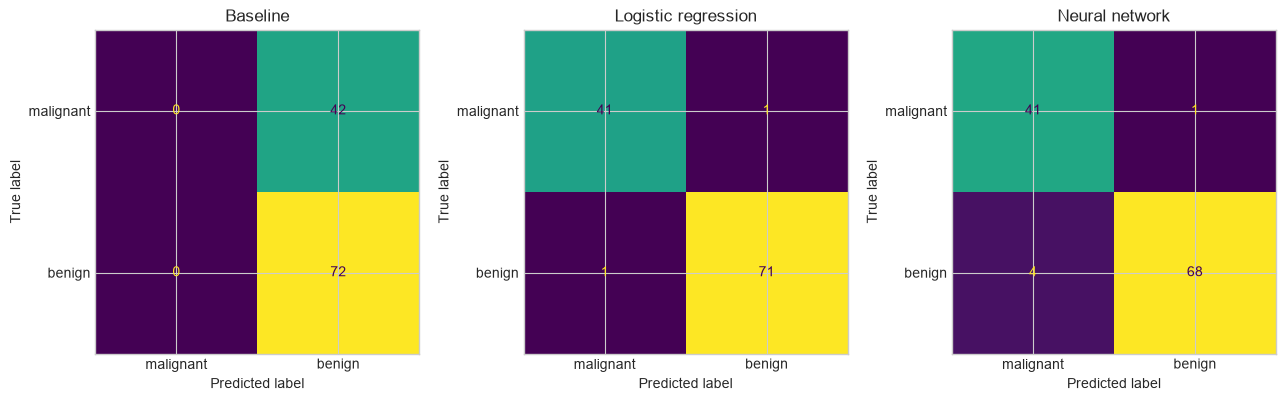

In [6]:
models = {
    "Baseline": baseline_model,
    "Logistic regression": logreg_model,
    "Neural network": mlp_model,
}

rows = []
confusion_matrices = {}
for name, model in models.items():
    preds = model.predict(X_test)
    rows.append({
        "accuracy": accuracy_score(y_test, preds),
        "precision_malignant": precision_score(y_test, preds, pos_label=0, zero_division=0),
        "recall_malignant": recall_score(y_test, preds, pos_label=0, zero_division=0),
    })
    confusion_matrices[name] = confusion_matrix(y_test, preds, labels=[0, 1])

comparison_table = pd.DataFrame(rows, index=models.keys())
baseline_cm = confusion_matrices["Baseline"]
logreg_cm = confusion_matrices["Logistic regression"]
mlp_cm = confusion_matrices["Neural network"]

display(comparison_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, cm, title in zip(
    axes,
    [baseline_cm, logreg_cm, mlp_cm],
    ["Baseline", "Logistic regression", "Neural network"],
):
    ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(
        ax=ax, colorbar=False
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()


### Checkpoint 3: Which classification errors matter in this example?

Using the confusion matrices above (rows are the actual class, columns are the predicted class, in `[malignant, benign]` order):

- For the logistic regression model and the neural network, how many malignant cases did each model incorrectly predict as benign (false negatives for malignant)? How many benign cases did each model incorrectly flag as malignant (false positives for malignant)?
- Which of those two error types is more costly in a screening context: missing an actual malignant case, or raising an unnecessary follow-up on a benign case? Why?
- Do the two models differ more in how many malignant cases they catch (recall), or in how many unnecessary false alarms they raise (precision)?

**Sample response:** Logistic regression misses 1 malignant case (1 false negative) and raises 1 unnecessary benign-flagged-as-malignant alarm (1 false positive). The neural network also misses 1 malignant case (1 false negative) but raises 4 false positives. Missing an actual malignant case (a false negative) is the more costly error in a screening context, since it means a real cancer is not flagged for follow-up, whereas a false positive mainly costs an unnecessary follow-up test. The two models catch the same number of malignant cases (recall is tied), but they differ mainly in precision: the neural network raises more unnecessary false alarms than logistic regression on this split.


## 6. Examine the neural network's training loss curve

After fitting, an `MLPClassifier` stores its per-iteration training loss in `loss_curve_`. This shows how the loss the optimizer was minimizing changed as training progressed. It is the training loss only: scikit-learn does not automatically provide a matching validation-loss curve the way the reading chapter's conceptual overfitting figure (Section 11.4) shows.


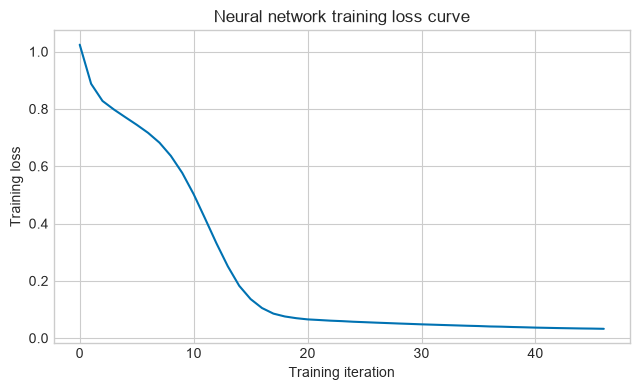

Iterations until early stopping: 47
First-iteration loss: 1.024
Final loss: 0.033


In [7]:
mlp_loss_curve = mlp_model.named_steps["clf"].loss_curve_

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(mlp_loss_curve, color="#0072B2")
ax.set_xlabel("Training iteration")
ax.set_ylabel("Training loss")
ax.set_title("Neural network training loss curve")
plt.tight_layout()
plt.show()

print(f"Iterations until early stopping: {len(mlp_loss_curve)}")
print(f"First-iteration loss: {mlp_loss_curve[0]:.3f}")
print(f"Final loss: {mlp_loss_curve[-1]:.3f}")


### Checkpoint 4: What can and cannot be concluded from the training loss curve?

- Describe the shape of the curve in one sentence: does the loss fall quickly then level off, fall steadily throughout, or something else?
- This curve shows only *training* loss. Does a steadily falling training loss, by itself, tell you whether the model generalizes to data it has not seen? What would you need to look at instead to answer that question? (Hint: you already computed it, in Step 5.)
- Suppose the loss curve had stopped after only 3-4 iterations with the loss barely lower than where it started. Would that be evidence the model learned a simple, efficient solution, or a sign that something went wrong? What would you check next?

**Sample response:** The curve falls quickly over the first several iterations and then levels off into a long, gently decreasing tail. A steadily falling *training* loss by itself only shows the network is fitting the training data better over time; it does not show whether that improvement transfers to new data. To answer the generalization question you need the held-out test-set metrics from Step 5 (accuracy, precision, recall on `X_test`), which were computed separately from this training-loss curve. A loss curve that flattened after only 3-4 iterations with almost no decrease would be a warning sign, not evidence of an efficient solution — it would suggest training stopped before the network learned much of anything (as happened with scikit-learn's bare-default early-stopping settings during this notebook's development), and the next step would be checking the test-set accuracy before trusting the model at all.


## 7. Recommend a model using evidence

### Quick check: critique an AI-generated claim

Suppose an AI assistant looked only at the accuracy numbers from Step 5 and wrote:

> "The neural network's test accuracy was lower than logistic regression's, so neural networks are generally worse than logistic regression for medical diagnosis tasks."

Using the comparison you built in this notebook, write a correction in a sentence or two. What does this notebook's comparison actually support a claim about, and what would it *not* be reasonable to conclude from one comparison on one dataset with one configuration?

**Sample response:** This conclusion over-generalizes from a single comparison. The neural network scored lower than logistic regression *on this one dataset, this one train/test split, and this one hyperparameter configuration*. That supports a narrow claim ("on this breast cancer screening task, with these settings, logistic regression performed at least as well as the neural network") but not a broad claim about neural networks in general. A different dataset, a different split, or different neural-network hyperparameters could change the comparison; one run is not enough evidence for a general rule about model families.


### Checkpoint 5 (final): Does the neural network justify its added complexity?

Write a short (4-6 sentence) evidence-based recommendation, addressing each point below using numbers and observations from this notebook, not a general impression:

- How do the three models compare on accuracy, precision, and recall (malignant as positive)? (Step 5)
- What did the training loss curve show, and what did it leave unresolved? (Step 6)
- Beyond the metrics, what other costs does the neural network carry compared to logistic regression (training time, stability across reruns, how easy each model is to explain to someone else)?
- Based on all of the above, would you recommend the neural network, the logistic regression model, or say the evidence does not clearly favor either? Why?
- What is one limitation of this entire comparison (dataset size, a single train/test split, the fact that this is a teaching dataset, or something else)?

**Sample response:** Both the logistic regression model (accuracy 0.982, malignant precision 0.976, malignant recall 0.976) and the neural network (accuracy 0.956, malignant precision 0.911, malignant recall 0.976) clearly beat the 0.632-accuracy baseline, and both catch the same 41 of 42 malignant test cases. Logistic regression makes fewer total errors overall (2 vs. 5), mainly because it raises fewer false-positive alarms. The training loss curve showed the network fitting steadily over 47 iterations down to a small training loss, but that curve alone did not establish the network would generalize well; the test-set comparison above is what actually answers that question, and it does not favor the network. Logistic regression is also faster to train, fully deterministic given the same data, and easier to explain (its coefficients are directly interpretable), while the neural network's results could shift somewhat with a different random seed. Given all of this, I would recommend logistic regression for this task: the neural network's added complexity is not justified here, since it does not outperform the simpler model and costs more to explain and retrain. One limitation of this whole comparison is that it rests on a single train/test split of a relatively small (569-row) teaching dataset; a more thorough comparison would repeat this with cross-validation or multiple random seeds before treating the conclusion as settled.
